# Aplicación integradora: del dNBR de Sentinel-2 a la comparación con el modelo de área quemada

Este cuaderno parte de los GeoTIFF mensuales de dNBR ya generados con `dnbr_mensual.py` y los archivos NetCDF del modelo Sparky v1.0 (`BAF_pred`). El flujo es el siguiente.

1. Se leen y se exploran las observaciones (dNBR mensual).
2. Se separa la señal estacional común del paisaje de los parches compactos que pueden corresponder a cicatrices de quema.
3. Se define una clasificación quemado / no quemado y se cuenta cada evento una sola vez.
4. Se agrega la clasificación a la grilla de 0.25° del modelo, lo que da una fracción quemada mensual observada.
5. Se lee y se explora el modelo.
6. Se llevan observación y modelo a la misma grilla, se comparan de forma descriptiva y se guardan como insumo de la PC6.

La región de ejemplo es una caja del norte de Bolivia. Los pasos se parametrizan para aplicarlos a otras regiones.

## 1. Configuración

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import xarray as xr

import dnbr_vis as dv
import dnbr_analisis as an

# Región y periodo
NOMBRE = "bolivia_beni"
BBOX = (-67.0, -14.0, -66.0, -13.0)      # oeste, sur, este, norte (múltiplos de 0.25)
ANIOS = [2019, 2020, 2021]

# Ubicación de los datos
RUTA_DNBR = "datos_pc6/salidas_dnbr"               # GeoTIFF generados con dnbr_mensual.py
RUTA_MODELO = "datos_pc6/modelo_BAF"             # archivos NetCDF del modelo (BAF_pred_<año>*.nc)

# Parámetros del análisis (provisionales; se calibran en las secciones siguientes)
UMBRAL = 0.35          # anomalía de dNBR desde la cual un píxel se considera quemado
VENTANA = 3            # meses previos revisados para no contar dos veces una cicatriz
MINIMO_VALIDO = 0.5    # fracción mínima de píxeles con dato para aceptar una celda de 0.25°

## 2. Observaciones: dNBR mensual

La lectura devuelve un arreglo de `xarray` con dimensiones (tiempo, lat, lon). El dNBR queda en sus unidades originales y los píxeles sin dato (nubes, sombras, agua) en NaN.

In [2]:
rutas = [f"{RUTA_DNBR}/dnbr_{NOMBRE}_{y}.tif" for y in ANIOS]
dnbr = dv.leer_dnbr(rutas)
print(dnbr.sizes)
print("Fracción de píxeles con dato por mes (primer año):")
print(np.round(dnbr.notnull().mean(("lat", "lon")).values[:12], 2))

Frozen({'tiempo': 36, 'lat': 1000, 'lon': 1000})
Fracción de píxeles con dato por mes (primer año):
[0.88 0.96 0.87 0.97 0.97 0.98 0.98 0.98 0.98 0.98 0.98 0.97]


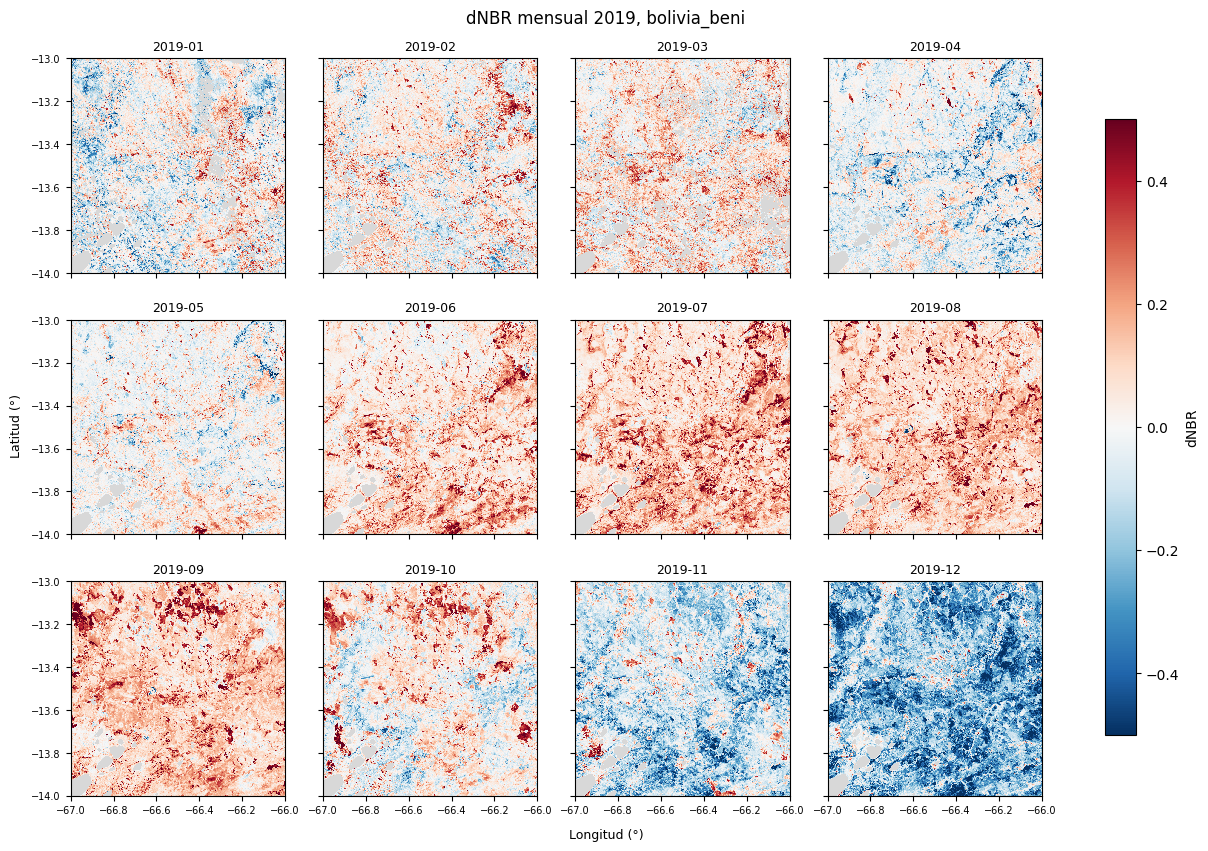

In [3]:
fig = dv.panel_mensual(dnbr.sel(tiempo=str(ANIOS[0])), vlim=0.5,
                       titulo=f"dNBR mensual {ANIOS[0]}, {NOMBRE}")

### Señal común a toda la caja

La mediana espacial resume lo que le ocurre al paisaje completo en cada mes.

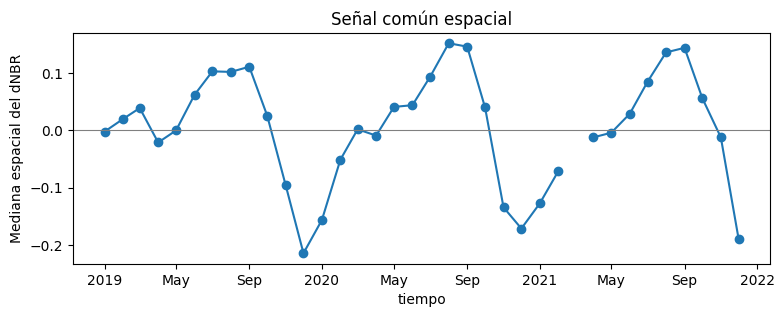

In [4]:
fondo = dnbr.median(dim=("lat", "lon"))
fig, ax = plt.subplots(figsize=(9, 3))
fondo.plot(ax=ax, marker="o")
ax.axhline(0, color="0.5", lw=0.8)
ax.set_ylabel("Mediana espacial del dNBR")
ax.set_title("Señal común espacial")
plt.show()

La mediana espacial sigue un ciclo estacional: aumenta durante la estación seca y desciende a valores negativos al reanudarse las lluvias. Ese comportamiento es consistente con la fenología de la vegetación frente a una línea base de tres meses que no es estacional, y no necesariamente con incendios. Si se aplicara un umbral al dNBR sin corregir esta señal, una parte grande de la caja quedaría marcada como quemada en la estación seca.

Sobre ese fondo se distinguen parches compactos de valores mucho más altos, que son los candidatos a cicatrices de quema. Su confirmación requiere una fuente independiente (focos de calor, productos de área quemada o imágenes en color verdadero).

## 3. Quitar la señal estacional común y elegir un umbral

Se resta a cada mes la mediana espacial de la caja. El resultado es una anomalía que resalta los píxeles que se desvían de su entorno. Este paso supone que menos de la mitad de la caja está quemada en un mes.

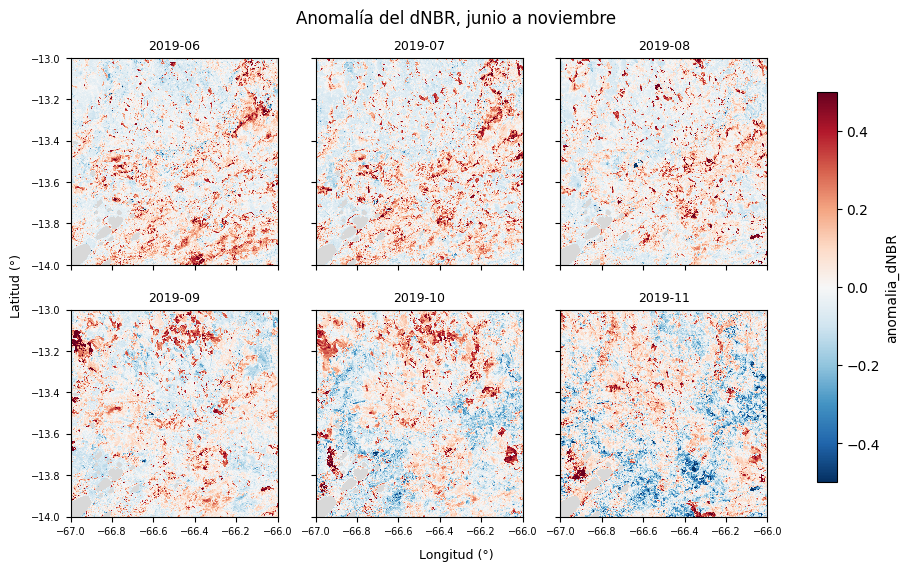

In [5]:
anom = an.anomalia_espacial(dnbr)
mes_ini, mes_fin = f"{ANIOS[0]}-06", f"{ANIOS[0]}-11"
fig = dv.panel_mensual(anom.sel(tiempo=slice(mes_ini, mes_fin)), vlim=0.5, ncols=3,
                       titulo="Anomalía del dNBR, junio a noviembre")

El umbral se elige mirando la distribución de la anomalía en los meses de mayor actividad. Los píxeles sin quema forman el cuerpo central de la distribución, y los quemados una cola hacia valores positivos.

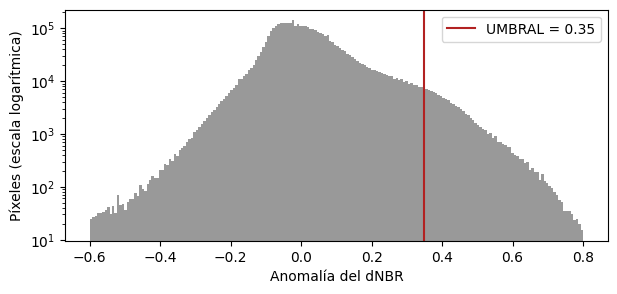

In [6]:
valores = anom.sel(tiempo=slice(f"{ANIOS[0]}-07", f"{ANIOS[0]}-10")).values.ravel()
valores = valores[~np.isnan(valores)]

fig, ax = plt.subplots(figsize=(7, 3))
ax.hist(valores, bins=200, range=(-0.6, 0.8), log=True, color="0.6")
ax.axvline(UMBRAL, color="firebrick", label=f"UMBRAL = {UMBRAL}")
ax.set_xlabel("Anomalía del dNBR")
ax.set_ylabel("Píxeles (escala logarítmica)")
ax.legend()
plt.show()

## 4. Mapa de quema y primer mes de detección

Una cicatriz sigue visible en los meses posteriores al incendio. Para obtener área quemada por mes, un píxel se cuenta solo en el primer mes en que aparece marcado y se excluye si ya lo estuvo en los meses previos de la ventana.

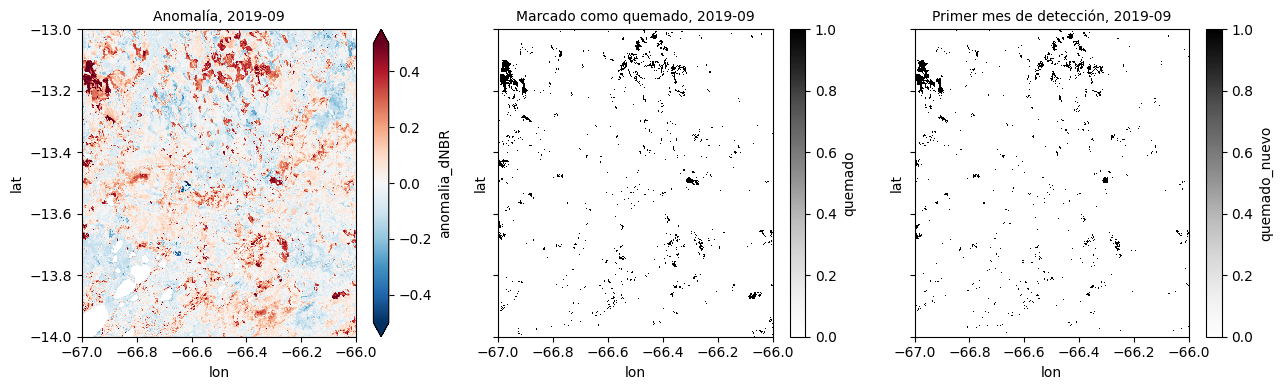

In [7]:
flag = an.marcar_quema(anom, UMBRAL)
nueva = an.quema_nueva(flag, VENTANA)

mes = f"{ANIOS[0]}-09"
fig, axs = plt.subplots(1, 3, figsize=(13, 4), sharex=True, sharey=True)
anom.sel(tiempo=mes).squeeze().plot(ax=axs[0], cmap="RdBu_r", vmin=-0.5, vmax=0.5)
flag.sel(tiempo=mes).squeeze().plot(ax=axs[1], cmap="Greys", vmin=0, vmax=1)
nueva.sel(tiempo=mes).squeeze().plot(ax=axs[2], cmap="Greys", vmin=0, vmax=1)
for ax, t in zip(axs, ["Anomalía", "Marcado como quemado", "Primer mes de detección"]):
    ax.set_title(f"{t}, {mes}", fontsize=10)
plt.tight_layout()
plt.show()

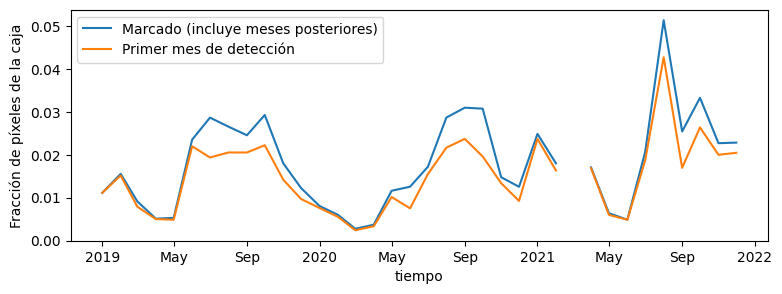

In [8]:
fig, ax = plt.subplots(figsize=(9, 3))
flag.mean(("lat", "lon")).plot(ax=ax, label="Marcado (incluye meses posteriores)")
nueva.mean(("lat", "lon")).plot(ax=ax, label="Primer mes de detección")
ax.set_ylabel("Fracción de píxeles de la caja")
ax.legend()
plt.show()

## 5. Fracción quemada observada en la grilla del modelo

Los bordes de la caja coinciden con la grilla de 0.25°, por lo que cada celda del modelo corresponde a un bloque exacto de píxeles. La fracción quemada observada de una celda es la proporción de píxeles marcados entre los píxeles con dato. Las celdas con pocos píxeles con dato se descartan.

Algunas limitaciones de esta estimación.
- Cada píxel de entrada representa unos 110 m (promedio de píxeles de 20 m), por lo que las cicatrices pequeñas quedan diluidas.
- El resultado depende del umbral y de la ventana, que son provisionales.
- Las nubes y sombras que escapan a la máscara pueden generar falsos positivos, y los meses con pocas observaciones pueden dejar eventos sin detectar.

Frozen({'tiempo': 36, 'lat': 4, 'lon': 4})


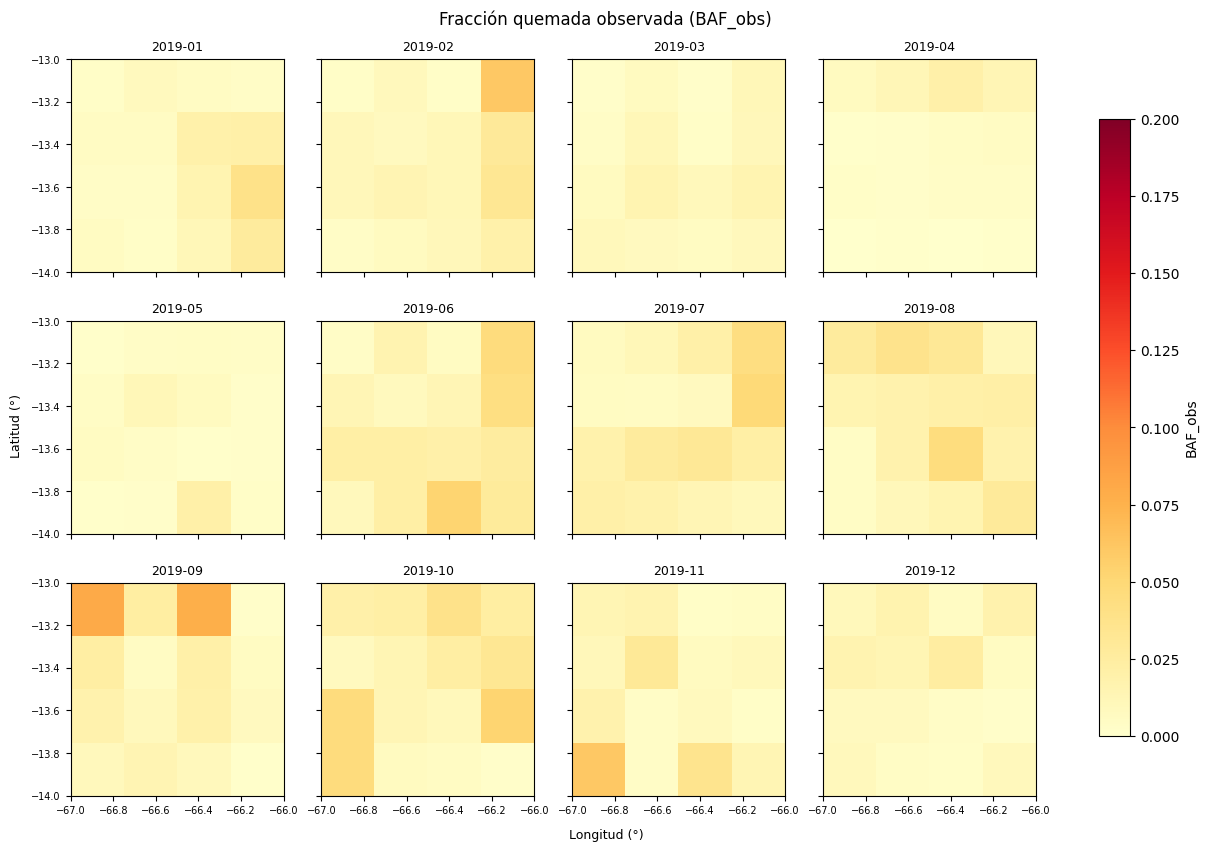

In [9]:
grilla = an.a_grilla_modelo(nueva, minimo_valido=MINIMO_VALIDO)
obs = grilla["BAF_obs"]
print(obs.sizes)
fig = dv.panel_mensual(obs.sel(tiempo=str(ANIOS[0])), vlim=0.2, vmin=0, cmap="YlOrRd",
                       titulo="Fracción quemada observada (BAF_obs)")

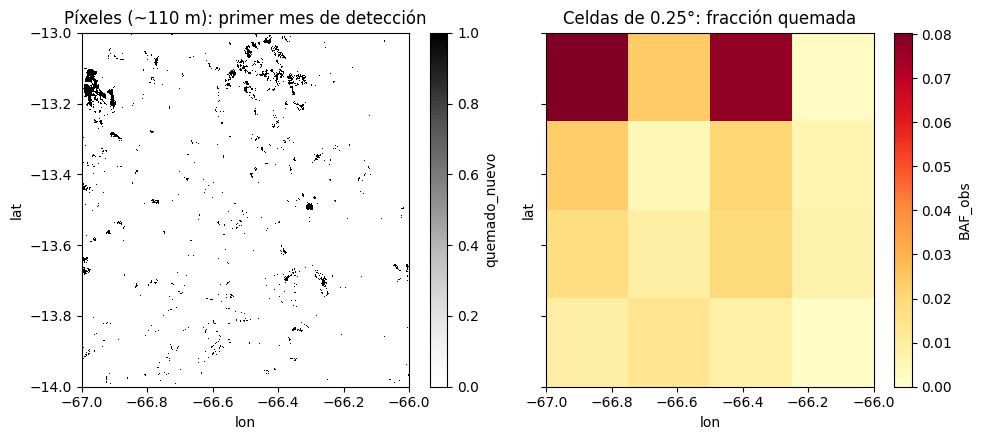

In [10]:
mes = "2019-09"
fig, axs = plt.subplots(1, 2, figsize=(10, 4.5), sharex=True, sharey=True)
nueva.sel(tiempo=mes).squeeze().plot(ax=axs[0], cmap="Greys", vmin=0, vmax=1)
axs[0].set_title("Píxeles (~110 m): primer mes de detección")
obs.sel(tiempo=mes).squeeze().plot(ax=axs[1], cmap="YlOrRd", vmin=0)
axs[1].set_title("Celdas de 0.25°: fracción quemada")
plt.tight_layout()
plt.show()

## 6. El modelo: lectura y exploración visual

El modelo entrega una fracción quemada mensual (`BAF_pred`) en la grilla de 0.25°. Es un producto modelado, entrenado con datos de satélite y forzado con ERA5 en el periodo histórico, no una observación. El atributo `product_type` indica si los archivos leídos corresponden al periodo histórico o a proyecciones.

In [11]:
modelo = an.leer_modelo(RUTA_MODELO, ANIOS, BBOX)
print(modelo.sizes)
print("product_type:", modelo.attrs["product_type"])

Frozen({'tiempo': 36, 'lat': 4, 'lon': 4})
product_type: Historical


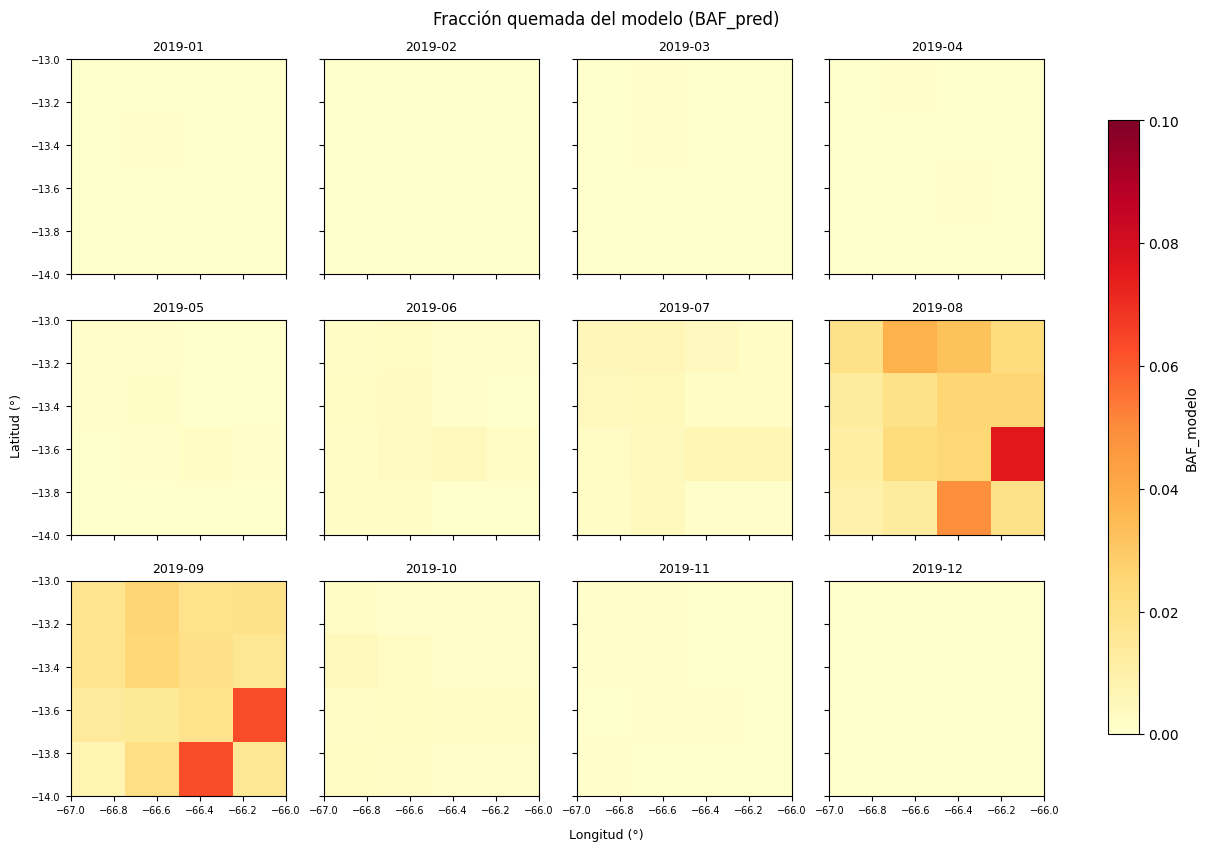

In [12]:
fig = dv.panel_mensual(modelo.sel(tiempo=str(ANIOS[0])), vlim=0.1, vmin=0, cmap="YlOrRd",
                       titulo="Fracción quemada del modelo (BAF_pred)")

La vista del dominio completo permite ubicar la caja de estudio dentro del patrón regional del modelo.

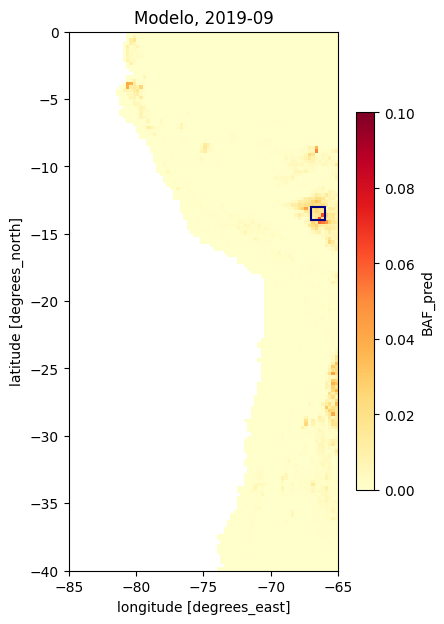

In [13]:
from matplotlib.patches import Rectangle

dominio = an.leer_modelo(RUTA_MODELO, [ANIOS[0]], (-85, -40, -65, 0))
mes_dom = f"{ANIOS[0]}-09"
fig, ax = plt.subplots(figsize=(4.5, 7))
dominio.sel(tiempo=mes_dom).squeeze().plot(ax=ax, cmap="YlOrRd", vmin=0, vmax=0.1,
                                           cbar_kwargs={"label": "BAF_pred", "shrink": 0.7})
o, s, e, n = BBOX
ax.add_patch(Rectangle((o, s), e - o, n - s, fill=False, edgecolor="navy", lw=1.5))
ax.set_aspect("equal")
ax.set_title(f"Modelo, {mes_dom}")
plt.show()

## 7. Observación y modelo en la misma grilla

Se seleccionan las mismas celdas y los mismos meses en ambos arreglos. A partir de aquí las dos fuentes son directamente comparables celda a celda y mes a mes.

In [14]:
obs, modelo = an.alinear(obs, modelo)
print(obs.sizes, modelo.sizes)
print("Mismas celdas:", bool((obs.lat == modelo.lat).all() and (obs.lon == modelo.lon).all()))

Frozen({'tiempo': 36, 'lat': 4, 'lon': 4}) Frozen({'tiempo': 36, 'lat': 4, 'lon': 4})
Mismas celdas: True


Esta comparación es solo descriptiva. Las definiciones de área quemada no coinciden por completo (la observación depende del umbral y de la ventana elegidos, y el modelo estima una fracción mensual por celda), de modo que las diferencias no se interpretan como error del modelo sin antes analizar la sensibilidad a esas decisiones. La validación cuantitativa corresponde a la PC6.

## Dato extra: Mapbiomas

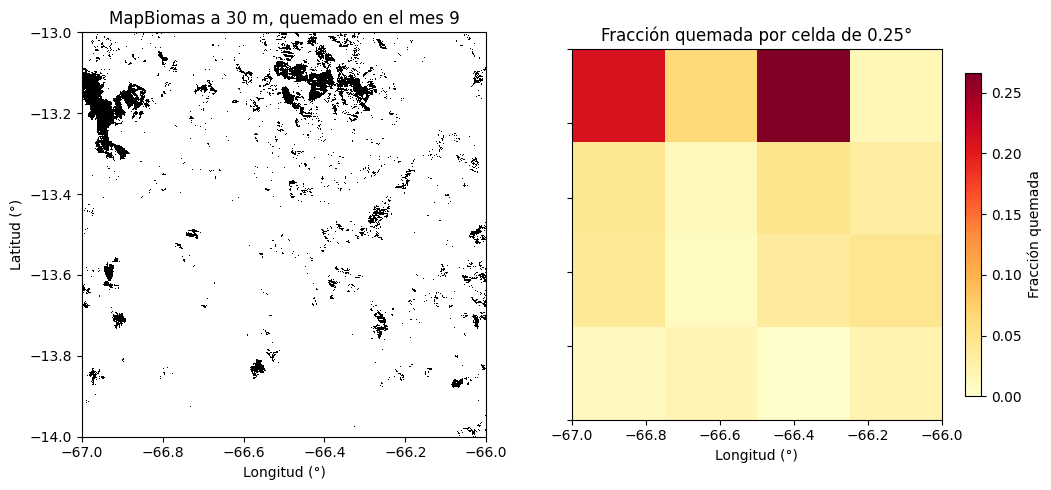

In [17]:
RUTA_MB = "mapbiomas_fuego/2019_fuego_bolivia.tif"   # ajustar

MES, ANIO = 9, 2019
oeste, sur, este, norte = BBOX
mb = an.leer_mapbiomas(RUTA_MB, BBOX, ANIO)

import rasterio
from rasterio.windows import Window


# Mapa a 30 m: se lee solo la ventana de la caja, sin agregar
with rasterio.open(RUTA_MB) as src:
    f0, c0 = src.index(oeste, norte)
    f1, c1 = src.index(este, sur)
    mes_quema = src.read(1, window=Window(c0, f0, c1 - c0, f1 - f0))

# Fracción quemada por celda de 0.25°
# 

ext = (oeste, este, sur, norte)
fig, axs = plt.subplots(1, 2, figsize=(11, 5), sharex=True, sharey=True)
axs[0].imshow(mes_quema == MES, extent=ext, cmap="Greys", interpolation="nearest")
axs[0].set_title(f"MapBiomas a 30 m, quemado en el mes {MES}")
im = axs[1].imshow(mb.isel(tiempo=MES - 1).values, extent=ext, cmap="YlOrRd",
                   vmin=0, interpolation="nearest")
axs[1].set_title("Fracción quemada por celda de 0.25°")
fig.colorbar(im, ax=axs[1], shrink=0.8, label="Fracción quemada")
for ax in axs:
    ax.set_xlabel("Longitud (°)")
axs[0].set_ylabel("Latitud (°)")
plt.tight_layout()


## 8. Insumos para la PC6

Se guarda un único archivo con la observación, el modelo y la fracción de píxeles con dato, ya alineados, junto con los parámetros usados.

In [22]:
# Mismas celdas y meses en las tres fuentes
obs, mb = an.alinear(obs, mb)


datos_areas_quemadas = xr.Dataset({
    "BAF_obs": obs,
    "BAF_mapbiomas": mb,
    "BAF_modelo": modelo,
    "frac_valida": grilla["frac_valida"].sel(tiempo=obs.tiempo),
})
datos_areas_quemadas.attrs.update(
    region=NOMBRE,
    bbox=str(BBOX),
    umbral=UMBRAL,
    ventana=VENTANA,
    minimo_valido=MINIMO_VALIDO,
    product_type_modelo=modelo.attrs.get("product_type", ""),
    anios_mapbiomas=str(sorted({int(a) for a in mb.tiempo.dt.year.values})),
)
datos_areas_quemadas.to_netcdf(f"datos_areas_quemadas_pc6.nc")
datos_areas_quemadas

<xarray.Dataset> Size: 10kB
Dimensions:        (lat: 4, lon: 4, tiempo: 36)
Coordinates:
  * lat            (lat) float64 32B -13.12 -13.38 -13.62 -13.88
  * lon            (lon) float64 32B -66.88 -66.62 -66.38 -66.12
  * tiempo         (tiempo) datetime64[ns] 288B 2019-01-01 ... 2021-12-01
Data variables:
    BAF_obs        (tiempo, lat, lon) float32 2kB 0.002812 0.008426 ... nan nan
    BAF_mapbiomas  (tiempo, lat, lon) float32 2kB 2.208e-05 2.324e-06 ... nan
    BAF_modelo     (tiempo, lat, lon) float32 2kB 0.0002228 ... 0.0001879
    frac_valida    (tiempo, lat, lon) float32 2kB 0.9048 0.9855 ... nan nan
Attributes:
    region:               bolivia_beni
    bbox:                 (-67.0, -14.0, -66.0, -13.0)
    umbral:               0.35
    ventana:              3
    minimo_valido:        0.5
    product_type_modelo:  Historical
    anios_mapbiomas:      [2019]

## 9. Aplicación a otras regiones

Los pasos se repiten cambiando `NOMBRE`, `BBOX` y `ANIOS` en la configuración. Antes de ejecutar conviene verificar lo siguiente.
- Los GeoTIFF de la región existen en `RUTA_DNBR` y siguen el patrón `dnbr_<nombre>_<año>.tif`.
- La caja está dentro del dominio de los archivos del modelo (85°W a 65°W y 40°S a 0°).
- En regiones con temporada de fuego que cruza el cambio de año, como Chile centro-sur, los meses de enero y febrero se asocian a la temporada del año anterior.
- El umbral se recalibra para cada región con el histograma de la sección 3, y se revisa que la fracción de píxeles con dato por mes sea razonable.